# A3 · E1 — Are the segments meaningful? (real data)

K-means on scaled behavioural features, fit on the training split only. k is chosen from
k = 2..10 by silhouette plus interpretability (`anchorai.discovery.segments.choose_k`).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anchorai.config import get_settings
from anchorai.features import build_features
from anchorai.scenario.tables import read_tables

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = get_settings().anchorai_seed
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

tables = read_tables()
members = tables["members"]
labels = members.set_index("member_id")
features = build_features(members)
is_train = labels["split"] == "train"
print(len(members), "members;", is_train.sum(), "train /", (~is_train).sum(), "test")

4000 members; 3200 train / 800 test


In [2]:
from anchorai.discovery import segments

seg = segments.fit_segments(features, labels["churn"], is_train, SEED)
sil = pd.Series(seg.card["silhouette_by_k"]).rename(int)
print("chosen k =", seg.card["k"], "| silhouette", round(seg.card["silhouette"], 3),
      "| stability ARI", round(seg.card["stability_ari"], 3), "(min", round(seg.card["stability_ari_min"], 3), ")")
sil.round(3).to_frame("silhouette").T

chosen k = 4 | silhouette 0.174 | stability ARI 1.0 (min 0.998 )


,2,3,4,5,6,7,8,9,10
silhouette,0.167,0.178,0.174,0.157,0.155,0.161,0.162,0.158,0.16


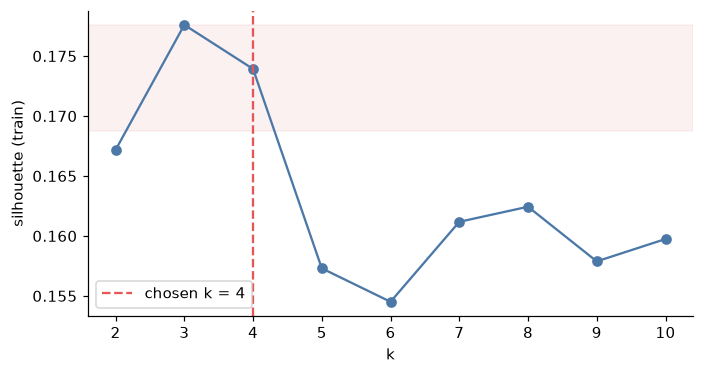

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(sil.index, sil.values, marker="o", color="#4c78a8")
ax.axvline(seg.card["k"], ls="--", color="#e45756", label=f"chosen k = {seg.card['k']}")
ax.axhspan((1 - segments.SILHOUETTE_TOLERANCE) * sil.loc[3:8].max(), sil.loc[3:8].max(), color="#e45756", alpha=0.08)
ax.set_xlabel("k"); ax.set_ylabel("silhouette (train)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "e1_silhouette.png"); plt.show()

In [4]:
profiles = seg.profiles.set_index("name")
profiles[["size", "churn_rate", *segments.SEGMENT_COLUMNS]].round(2)

,size,churn_rate,lifetime,avg_class_frequency_total,trend_ratio,contract_period,avg_additional_charges_total,age,group_visits
name,,,,,,,,,
New and slipping,728,0.95,0.93,1.29,0.48,1.77,111.81,26.42,0.23
Established solo trainers,1365,0.17,4.19,1.99,1.02,2.49,150.28,29.73,0.00
Established class-goers,961,0.13,4.21,2.02,1.00,2.79,151.96,29.83,1.00
Annual-contract loyalists,946,0.01,4.71,2.03,1.01,12.00,164.06,29.87,0.55


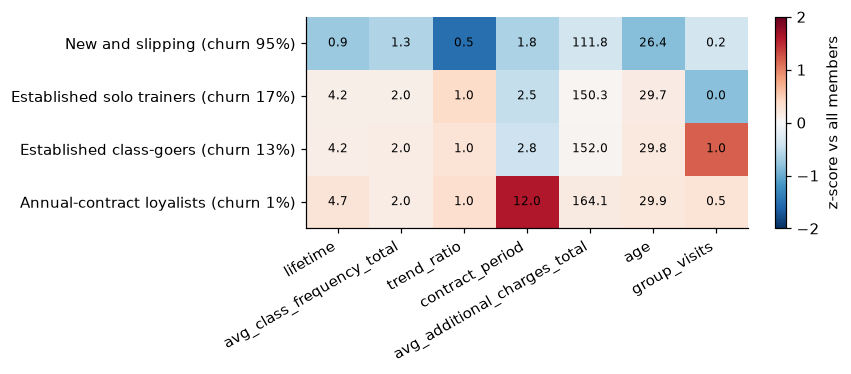

In [5]:
cols = segments.SEGMENT_COLUMNS
z = (profiles[cols] - features[cols].mean()) / features[cols].std()
fig, ax = plt.subplots(figsize=(8, 3.5))
im = ax.imshow(z.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(cols)), cols, rotation=30, ha="right")
ax.set_yticks(range(len(z)), [f"{n} (churn {r:.0%})" for n, r in zip(z.index, profiles["churn_rate"])])
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{profiles[cols].iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="z-score vs all members")
fig.tight_layout(); fig.savefig(FIG / "e1_profiles.png"); plt.show()

## Stability across seeds and generalisation to the test split

In [6]:
from sklearn.metrics import adjusted_rand_score

stability = pd.Series({s: segments.fit_segments(features, labels["churn"], is_train, s).labels for s in range(SEED, SEED + 5)})
ari = pd.DataFrame([[adjusted_rand_score(a, b) for b in stability] for a in stability], index=stability.index, columns=stability.index)
test_share = seg.labels[~is_train].value_counts(normalize=True).sort_index()
train_share = seg.labels[is_train].value_counts(normalize=True).sort_index()
pd.DataFrame({"train share": train_share, "test share": test_share}).round(3), ari.round(3)

(            train share  test share
 segment_id                         
 0                 0.182       0.184
 1                 0.348       0.316
 2                 0.243       0.230
 3                 0.228       0.270,
        42     43     44     45     46
 42  1.000  1.000  0.998  1.000  1.000
 43  1.000  1.000  0.998  1.000  1.000
 44  0.998  0.998  1.000  0.998  0.998
 45  1.000  1.000  0.998  1.000  1.000
 46  1.000  1.000  0.998  1.000  1.000)

In [7]:
table = profiles[["size", "churn_rate", *cols]].round(3)
table.to_csv(RES / "e1_segment_profiles.csv")
sil.to_csv(RES / "e1_silhouette_by_k.csv", header=["silhouette"])
print("E1: k =", seg.card["k"], "silhouette =", round(seg.card["silhouette"], 3), "mean ARI =", round(ari.values[np.triu_indices(5, 1)].mean(), 3))

E1: k = 4 silhouette = 0.174 mean ARI = 0.999


**Reading.** Silhouette is low and nearly flat across k (behavioural data is not cleanly
clustered), so k is not decided by silhouette alone: the most detailed k within 5% of the best
score is taken. The clusters are nevertheless highly stable across seeds and separate churn
rates sharply, which is what the retention planner needs.